## Listes de 9 questions

Quand et comment les clients commandent-ils généralement ?  

Quels produits faut-il mettre en avant le samedi ?  

Quels autres produits les clients commandent-ils fréquemment avec du chocolat ?  

Quels sont les principaux profils de clients : acheteurs nocturnes, acheteurs occasionnels ou accros au  panier ?

Quel article les clients ajoutent-ils en premier à leur panier ?

Quels produits ont le plus de chances d’être commandés à nouveau ?

Les clients commandent-ils en moyenne plus de nourriture pour chats le matin que de nourriture pour chiens le soir ?

Existe-t-il une corrélation entre l’heure de la dernière commande et la probabilité de recommander un produit ?

Peut-on prédire si un produit sera commandé à nouveau par un client lors de sa prochaine visite ?

Importation des modules

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Ouverture des fichiers 

In [21]:
df_aisles = pd.read_csv("./datasets/aisles.csv")
df_departments = pd.read_csv("./datasets/departments.csv")
df_order_products = pd.read_csv("./datasets/order_products.csv")
df_orders = pd.read_csv("./datasets/orders.csv")
df_products = pd.read_csv("./datasets/products.csv")

Display que les 10 premières lignes

In [22]:
display(df_aisles.head(10))
display(df_departments.head(10))
display(df_order_products.head(10))
display(df_orders.head(10))
display(df_products.head(10))

,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation
5,6,other
6,7,packaged meat
7,8,bakery desserts
8,9,pasta sauce
9,10,kitchen supplies


,department_id,department
0,1,frozen
1,2,other
2,3,bakery
3,4,produce
4,5,alcohol
5,6,international
6,7,beverages
7,8,pets
8,9,dry goods pasta
9,10,bulk


,order_id,product_id,add_to_cart_order,reordered
0,2,33120.0,1.0,1.0
1,2,28985.0,2.0,1.0
2,2,9327.0,3.0,0.0
3,2,45918.0,4.0,1.0
4,2,30035.0,5.0,0.0
5,2,17794.0,6.0,1.0
6,2,40141.0,7.0,1.0
7,2,1819.0,8.0,1.0
8,2,43668.0,9.0,0.0
9,4,46842.0,1.0,0.0


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1.0,1.0,2.0,8.0,NaN
1,2398795,1.0,2.0,3.0,7.0,15.0
2,473747,1.0,3.0,3.0,12.0,21.0
3,2254736,1.0,4.0,4.0,7.0,29.0
4,431534,1.0,5.0,4.0,15.0,28.0
5,2295261,1.0,9.0,1.0,16.0,0.0
6,2550362,1.0,10.0,4.0,8.0,30.0
7,2168274,2.0,1.0,2.0,11.0,NaN
8,839880,2.0,14.0,3.0,10.0,13.0
9,444309,3.0,2.0,3.0,19.0,9.0


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13
5,6,Dry Nose Oil,11,11
6,7,Pure Coconut Water With Orange,98,7
7,8,Cut Russet Potatoes Steam N' Mash,116,1
8,9,Light Strawberry Blueberry Yogurt,120,16
9,10,Sparkling Orange Juice & Prickly Pear Beverage,115,7


Vérifications qu'il n'y a pas de valeurs nul.

In [23]:
display(df_aisles.isnull().sum())
display(df_departments.isnull().sum())
display(df_order_products.isnull().sum())
display(df_orders.isnull().sum())
display(df_products.isnull().sum())

aisle_id    0
aisle       0
dtype: int64

department_id    0
department       0
dtype: int64

order_id               0
product_id           449
add_to_cart_order    446
reordered            449
dtype: int64

order_id                      0
user_id                      31
order_number                 23
order_dow                    22
order_hour_of_day            23
days_since_prior_order    86909
dtype: int64

product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64

Affichage des dimension de chaque csv

In [24]:
display(df_aisles.shape)
display(df_departments.shape)
display(df_order_products.shape)
display(df_orders.shape)
display(df_products.shape)

(134, 2)

(21, 2)

(13692886, 4)

(1444444, 6)

(49688, 4)

Enlever les espaces invisibles

In [25]:
df_products["product_name"] = df_products["product_name"].str.strip()
df_departments["department"] = df_departments["department"].str.strip()
df_aisles["aisle"] = df_aisles["aisle"].str.strip()

## Quand et comment les clients commandent-ils généralement ?  

Ces lignes servent à compter et trier le nombre de commandes par heure et par fréquence d'achat afin d'identifier précisément les habitudes de consommation de tes clients dans le temps.

In [26]:
df_orders_hour = df_orders["order_hour_of_day"].value_counts().sort_index()
df_orders_day = df_orders["days_since_prior_order"].value_counts().sort_index()
display(df_orders_hour)
display(df_orders_day)

order_hour_of_day
0.0       9608
1.0       5213
2.0       3189
3.0       2280
4.0       2345
5.0       4062
6.0      12997
7.0      38687
8.0      75137
9.0     109220
10.0    122020
11.0    119964
12.0    114884
13.0    117439
14.0    119428
15.0    119754
16.0    115372
17.0     96566
18.0     77587
19.0     59275
20.0     43848
21.0     32721
22.0     26100
23.0     16725
Name: count, dtype: int64

days_since_prior_order
0.0      28838
1.0      61306
2.0      81468
3.0      91809
4.0      93821
5.0      90812
6.0     101095
7.0     134830
8.0      76438
9.0      49678
10.0     40298
11.0     34287
12.0     32145
13.0     35325
14.0     42149
15.0     28224
16.0     19851
17.0     16569
18.0     15263
19.0     14467
20.0     16322
21.0     19174
22.0     13538
23.0     10061
24.0      8701
25.0      8179
26.0      8122
27.0      9290
28.0     11280
29.0      8068
30.0    156127
Name: count, dtype: int64

Quand les clients commandent-ils généralement ?  

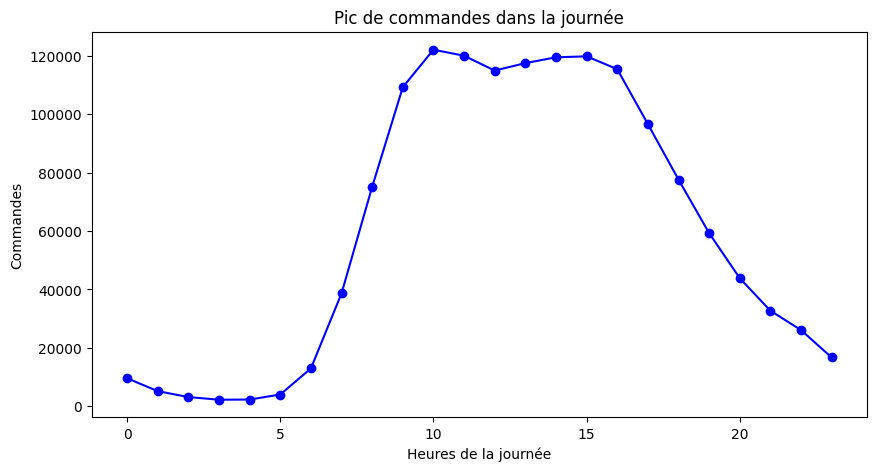

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(df_orders_hour.index, df_orders_hour.values, marker="o", color="blue")
plt.title("Pic de commandes dans la journée")
plt.xlabel("Heures de la journée")
plt.ylabel("Commandes")
plt.show()

>Le pic matinal : L'affluence maximale se situe autour de 10h du matin. Les clients ont donc tendance à organiser leurs courses en ligne en milieu de matinée plutôt que le soir.

comment les clients commandent-ils généralement ?  

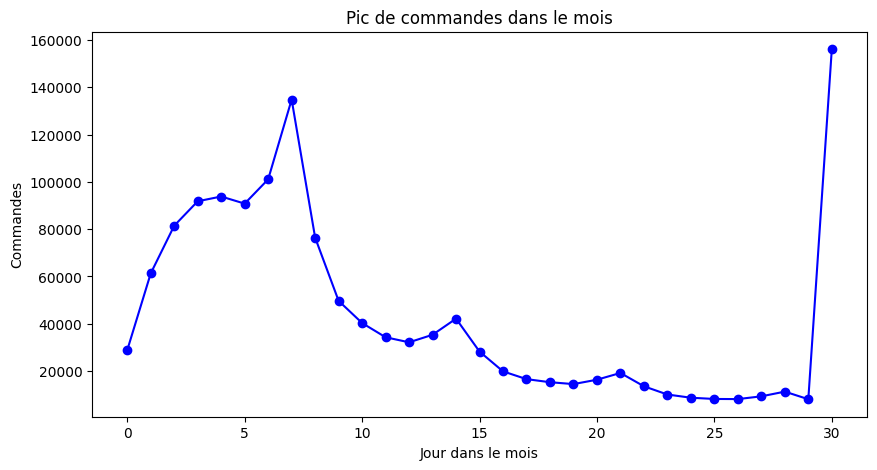

In [28]:
df_orders_hour = df_orders["order_hour_of_day"].value_counts().sort_index()
df_orders_day = df_orders["days_since_prior_order"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(df_orders_day.index, df_orders_day.values, marker="o", color="blue")
plt.title("Pic de commandes dans le mois")
plt.xlabel("Jour dans le mois")
plt.ylabel("Commandes")
plt.show()

>La routine hebdomadaire : On observe des rebonds de commandes très nets tous les 7, 14 et 21 jours. Cela met en lumière une routine bien ancrée chez les familles, qui effectuent leurs achats de manière très régulière, semaine après semaine.

>Le grand ravitaillement mensuel : Le pic le plus important se trouve à 30 jours. Il correspond aux clients qui font un gros "plein" une fois par mois (souvent après la paie), mais il représente aussi un plafond technique de la base de données qui regroupe toutes les commandes espacées de 30 jours et plus.

## Quels produits faut-il mettre en avant le samedi ?  

Cela permet d'identifier les 10 produits les plus vendus le samedi en croisant les données des commandes, des paniers et des noms de produits. Il calcule également la distribution globale des ventes par identifiant de produit pour ce jour précis.

In [29]:
df_orders_saturday = df_orders[df_orders["order_dow"] == 6]
df_sat_prod = pd.merge(df_orders_saturday, df_order_products, on="order_id")
df_final = pd.merge(df_sat_prod, df_products, on="product_id")
top_10_sat = df_final["product_name"].value_counts().head(10)
df_orders_sat = df_sat_prod["product_id"].value_counts().sort_index()

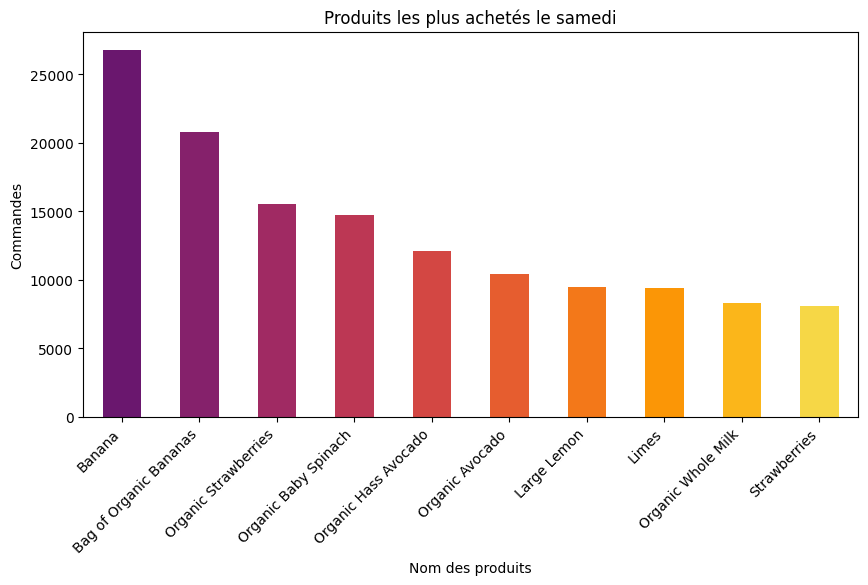

In [30]:
couleurs = plt.cm.inferno(np.linspace(0.3, 0.9, 10))
plt.figure(figsize=(10, 5))
top_10_sat.plot(kind="bar", color=couleurs)
plt.xticks(rotation=45, ha="right")
plt.title("Produits les plus achetés le samedi")
plt.xlabel("Nom des produits")
plt.ylabel("Commandes")
plt.show()

>Au vu des données, nous recommandons de mettre fortement en avant les bananes le samedi, car il y a plus de 25 000 commandes pour ce produit ce jour-là.

## Quels autres produits les clients commandent-ils fréquemment avec du chocolat ?  


Ce code analyse les habitudes d'achat pour identifier les 10 produits les plus fréquemment achetés en même temps que du chocolat.

In [31]:
df_chocolat = df_products[df_products["product_name"].str.contains("Chocolate", na=False)]
df_chocolat_panier = pd.merge(df_chocolat, df_order_products, on="product_id")
df_chocolat_final = df_chocolat_panier["order_id"]
df_product_article = df_order_products[df_order_products["order_id"].isin(df_chocolat_final)]
df_nom_finaux = pd.merge(df_product_article, df_products, on="product_id")
df_final_all = pd.merge(df_nom_finaux, df_orders, on="order_id")
produit_avec_chocolat = df_nom_finaux["product_name"].value_counts().head(10)

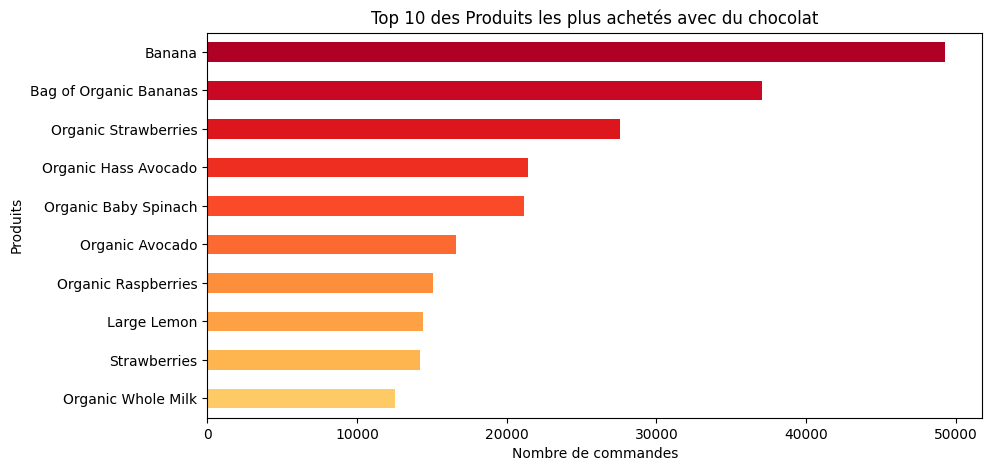

In [32]:
couleurs = plt.cm.YlOrRd(np.linspace(0.9, 0.3, 10))
plt.figure(figsize=(10, 5))
produit_avec_chocolat.plot(kind="barh", color=couleurs)
plt.title("Top 10 des Produits les plus achetés avec du chocolat")
plt.xlabel("Nombre de commandes")
plt.ylabel("Produits")
plt.gca().invert_yaxis()
plt.show()

>On en conclut donc que, même en achetant du chocolat, les bananes dominent largement les paniers des clients.

>En conclusion, même lors d'un achat plaisir comme le chocolat, les bananes et les produits frais continuent de dominer largement le panier des clients.

Importation des modules

In [33]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import joblib

Affichage des valeurs nuls totale du fichier dataset df_final_all

In [34]:
print(df_final_all.isna().sum())

order_id                       0
product_id                     0
add_to_cart_order            121
reordered                    149
product_name                   0
aisle_id                       0
department_id                  0
user_id                      156
order_number                 129
order_dow                     62
order_hour_of_day             46
days_since_prior_order    244672
dtype: int64


Le code prépare ses données pour le Machine Learning en remplaçant les valeurs manquantes et en transformant les noms de produits textuels en identifiants numériques via un LabelEncoder.

In [35]:
encoders = {}

le_product_name = LabelEncoder()
df_final_all["days_since_prior_order"] = df_final_all["days_since_prior_order"].fillna(0)
df_final_all = df_final_all.dropna(subset=["reordered"])
df_final_all["product_name"] = le_product_name.fit_transform(df_final_all["product_name"].astype(str))
encoders["product_name_le"] = le_product_name

LE code définit les variables d'entrée X et la cible y, divise les données en ensembles d'entraînement et de test, puis entraîne un modèle Random Forest pour prédire la probabilité de réachat d'un produit.

In [36]:
X = df_final_all[["order_hour_of_day", "order_dow", "days_since_prior_order", "product_name", "add_to_cart_order"]]
y = df_final_all["reordered"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
modele = RandomForestClassifier(n_estimators=100, max_depth=15, class_weight="balanced", n_jobs=-1).fit(X=X_train, y=y_train)
y_pred = modele.predict(X_test)

Le code permet d'évaluer la précision et la performance du modèle de Machine Learning en comparant ses prédictions aux résultats réels.

In [37]:
accuracy = accuracy_score(y_test, y_pred)
classification_report = classification_report(y_test, y_pred)
print(accuracy)
print(classification_report)

0.653600653193691
              precision    recall  f1-score   support

         0.0       0.57      0.55      0.56    313999
         1.0       0.70      0.72      0.71    464943

    accuracy                           0.65    778942
   macro avg       0.64      0.64      0.64    778942
weighted avg       0.65      0.65      0.65    778942



Ce code sert à sauvegarder le travail sur le disque dur pour pouvoir l'utiliser plus tard dans le dashboard Streamlit sans avoir à tout recalculer.

In [38]:
joblib.dump(modele, "model.joblib")
joblib.dump(X_train.columns.tolist(), "model_columns.joblib")
joblib.dump(encoders, "encoders.joblib")

['encoders.joblib']

Erreur faites

-J'ai d'abord tenté d'utiliser un RandomForestRegressor, avant de réaliser qu'un classifieur était nécessaire pour prédire la variable binaire de réachat et obtenir des probabilités précises car binaire.

-Le dashboard était initialement très lent car il rechargeait le modèle et les données à chaque action, ce qui m'a poussé à implémenter un système de mise en cache avec @st.cache_resource (sans cache c'est comme si je devais tout relire à chaque fois)

-Au debut pour mon modèle il ne marchait pas parce que, il avait des valeurs en texte donc j'ai du les transformer en données numériques avec label Encoder.